Total number of samples: 150
Training samples: 120
Testing samples: 30

Initial random weights:
Iris-setosa : [0.04869460564382222, 0.2505409503856707, 0.24730672940960408, 0.3650451239500099]
Iris-versicolor : [-0.21409320509638308, 0.46557246336451585, 0.06674002902069132, 0.2473890969585898]
Iris-virginica : [0.2548983161359918, 0.42919945567821527, -0.22588777800725623, -0.1333781867816134]
Epoch: 1 | Test Accuracy: 33.33 %
Epoch: 2 | Test Accuracy: 33.33 %
Epoch: 3 | Test Accuracy: 33.33 %
Epoch: 4 | Test Accuracy: 33.33 %
Epoch: 5 | Test Accuracy: 66.67 %
Epoch: 6 | Test Accuracy: 63.33 %
Epoch: 7 | Test Accuracy: 63.33 %
Epoch: 8 | Test Accuracy: 60.0 %
Epoch: 9 | Test Accuracy: 60.0 %
Epoch: 10 | Test Accuracy: 66.67 %
Epoch: 11 | Test Accuracy: 66.67 %
Epoch: 12 | Test Accuracy: 66.67 %
Epoch: 13 | Test Accuracy: 66.67 %
Epoch: 14 | Test Accuracy: 60.0 %
Epoch: 15 | Test Accuracy: 66.67 %
Epoch: 16 | Test Accuracy: 66.67 %
Epoch: 17 | Test Accuracy: 66.67 %
Epoch: 18 | Test Ac

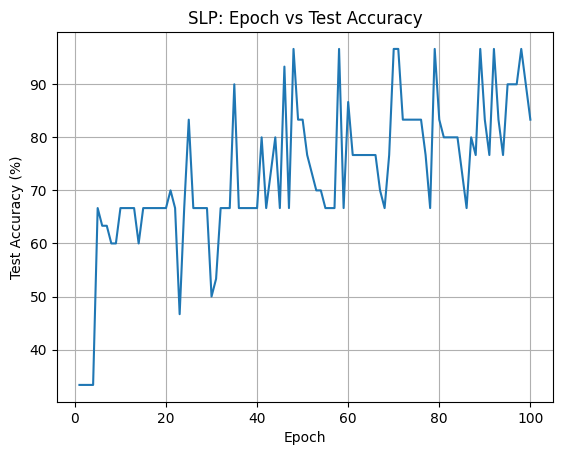

In [1]:
import random
import matplotlib.pyplot as plt



# Read the data set


file = open("/content/iris data set.csv", "r")

# Skip the header line
header = file.readline()

features = []
labels = []

for line in file:
    line = line.strip()

    if line != "":
        # Use tab as delimiter since the file is tab-separated
        values = line.split("\t")

        flower_features = []
        for i in range(4):
            flower_features.append(float(values[i]))

        flower_label = values[4]

        features.append(flower_features)
        labels.append(flower_label)

file.close()

classes = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]

print("Total number of samples:", len(features))



# SPLIT DATA INTO TRAINING AND TESTING DATA


train_features = []
train_labels = []
test_features = []
test_labels = []

for i in range(len(features)):
    if i % 5 == 0:
        test_features.append(features[i])
        test_labels.append(labels[i])
    else:
        train_features.append(features[i])
        train_labels.append(labels[i])

print("Training samples:", len(train_features))
print("Testing samples:", len(test_features))



# NORMALIZE THE INPUT FEATURES




minimum = []
maximum = []

for column in range(4):
    smallest = train_features[0][column]
    largest = train_features[0][column]

    for row in range(len(train_features)):
        value = train_features[row][column]

        if value < smallest:
            smallest = value

        if value > largest:
            largest = value

    minimum.append(smallest)
    maximum.append(largest)


# Normalize training data to approximately the range 0 to 1.

normalized_train = []

for row in range(len(train_features)):
    new_row = []

    for column in range(4):
        difference = maximum[column] - minimum[column]

        if difference != 0:
            value = (train_features[row][column] - minimum[column]) / difference
        else:
            value = 0.0

        new_row.append(value)

    normalized_train.append(new_row)


# Normalize testing data using training minimum and maximum values.

normalized_test = []

for row in range(len(test_features)):
    new_row = []

    for column in range(4):
        difference = maximum[column] - minimum[column]

        if difference != 0:
            value = (test_features[row][column] - minimum[column]) / difference
        else:
            value = 0.0

        new_row.append(value)

    normalized_test.append(new_row)



# RANDOMLY INITIALIZE WEIGHTS AND BIASES


random.seed(35)

weights = []

for class_number in range(3):
    one_class_weights = []

    for feature_number in range(4):
        random_weight = random.uniform(-0.5, 0.5)
        one_class_weights.append(random_weight)

    weights.append(one_class_weights)

# Biases are initialized to zero.
bias = [0.0, 0.0, 0.0]

learning_rate = 0.1
number_of_epochs = 100

print("\nInitial random weights:")
for class_number in range(3):
    print(classes[class_number], ":", weights[class_number])



# PREDICTION FUNCTION


def predict(input_values):

    scores = []

    # Calculate one score for each class.
    for class_number in range(3):
        total = bias[class_number]

        for feature_number in range(4):
            total = total + (
                weights[class_number][feature_number]
                * input_values[feature_number]
            )

        scores.append(total)

    # Find the class having the highest score.
    best_class = 0

    for class_number in range(1, 3):
        if scores[class_number] > scores[best_class]:
            best_class = class_number

    return best_class



# TRAIN THE SINGLE LAYER PERCEPTRON


accuracy_history = []

for epoch in range(number_of_epochs):


    for row in range(len(normalized_train)):

        input_values = normalized_train[row]
        actual_label = train_labels[row]


        if actual_label == "Iris-setosa":
            actual_class = 0
        elif actual_label == "Iris-versicolor":
            actual_class = 1
        else:
            actual_class = 2


        predicted_class = predict(input_values)


        if predicted_class != actual_class:

            for feature_number in range(4):


                weights[actual_class][feature_number] = (
                    weights[actual_class][feature_number]
                    + learning_rate * input_values[feature_number]
                )


                weights[predicted_class][feature_number] = (
                    weights[predicted_class][feature_number]
                    - learning_rate * input_values[feature_number]
                )


            bias[actual_class] = bias[actual_class] + learning_rate
            bias[predicted_class] = bias[predicted_class] - learning_rate


    # CALCULATE TEST ACCURACY AFTER EACH EPOCH


    correct_predictions = 0

    for row in range(len(normalized_test)):

        predicted_class = predict(normalized_test[row])
        actual_label = test_labels[row]

        if actual_label == "Iris-setosa":
            actual_class = 0
        elif actual_label == "Iris-versicolor":
            actual_class = 1
        else:
            actual_class = 2

        if predicted_class == actual_class:
            correct_predictions = correct_predictions + 1

    accuracy = (correct_predictions / len(normalized_test)) * 100
    accuracy_history.append(accuracy)

    print("Epoch:", epoch + 1, "| Test Accuracy:", round(accuracy, 2), "%")



# DISPLAY FINAL ACCURACY


print("\nFinal Test Accuracy:", round(accuracy_history[-1], 2), "%")



# PLOT EPOCH VS ACCURACY


epochs = []

for i in range(number_of_epochs):
    epochs.append(i + 1)

plt.plot(epochs, accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("SLP: Epoch vs Test Accuracy")
plt.grid(True)
plt.show()